In [24]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/microsoft234/Microsoft.csv


# Week 8 Tutorial: Introduction to Python with Microsoft Data

FIN-10001 Methods for Finance | Level 4

In Kaggle, type each code block into its own cell and press Shift + Enter to run it.

# Step 1: Python as a calculator

## Addition, subtraction, multiplication, division

In [11]:

10 + 5

15

In [9]:
print(10 - 5)

5


In [10]:
print(10 * 5)
print(10 / 5)

# Powers (10 squared)
print(10 ** 2)

# A finance example: buy at £100, sell at £110
print((110 - 100) / 100)

50
2.0
100
0.1


# Step 2: Naming variables

In [13]:
# A variable is a labelled box that stores a value
buy_price = 100
sell_price = 110

In [14]:
# Use the names in a calculation
simple_return = (sell_price - buy_price) / buy_price
print(simple_return)

0.1


In [15]:
# Show the return as a percentage
print(simple_return * 100, "%")

10.0 %


## Rules for names:

- No spaces (use _), e.g. buy_price
- Don’t start with a number
- Python is case-sensitive, so Price and price are different
- Choose clear names: close_price is better than x

# Step 3: What is a string and what is numeric?

In [16]:
# Numeric data: numbers you can do maths with
price = 480.57        # float (has a decimal point)
shares = 20           # integer (whole number)

In [17]:
# String data: text, always inside quotation marks
company = "Microsoft"
ticker = "MSFT"

In [18]:
# Check the type
print(type(price))     # float
print(type(shares))    # int
print(type(company))   # str (string)

<class 'float'>
<class 'int'>
<class 'str'>


In [19]:
# Why the difference matters
print(5 + 5)       # numeric: 10
print("5" + "5")   # string: "55" (joined, not added)

10
55


## Key idea: anything inside quotation marks is a string, even if it looks like a number.

Numeric data (prices, returns) can be added, averaged and plotted.
Categorical/string data (company name, sector) is used for labelling and grouping.

# Step 4: Using string variables

In [2]:
company = "Microsoft"
ticker = "MSFT"

# 1. Join strings with +
print(company + " (" + ticker + ")")

Microsoft (MSFT)


In [3]:
# 2. Mix text and numbers using an f-string (put f before the quotes)
price = 480.57
print(f"{company} closed at ${price}")

Microsoft closed at $480.57


In [4]:
# 3. Useful string tools
print(company.upper())    # MICROSOFT
print(company.lower())    # microsoft
print(len(company))       # 9 letters

MICROSOFT
microsoft
9


In [5]:
# A finance sentence built from variables
buy_price = 39.61
sell_price = 480.57
total_return = (sell_price - buy_price) / buy_price * 100

print(f"{company} returned {total_return:.2f}% from 2015 to 2025")

Microsoft returned 1113.25% from 2015 to 2025


:.2f means “show 2 decimal places”.
Common mistake: "Price: " + price gives an error because you can’t join text and a number with +. Use an f-string.

# Step 5: Python libraries

## What is a library? 
A library is a set of pre-written code that someone else has built and tested. Instead of writing everything from scratch, we borrow these ready-made tools.

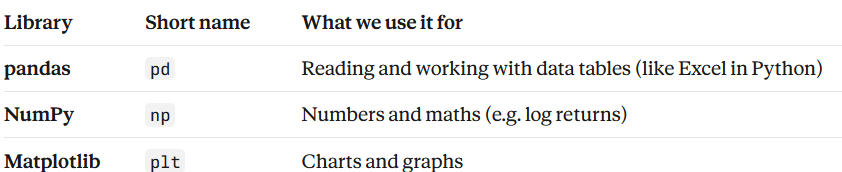

In [6]:
# Load the libraries (run this first, every session)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded!")

Libraries loaded!


as pd, as np and as plt are short nicknames, so we can type pd instead of pandas every time.
If you skip this cell, you will get: NameError: name 'pd' is not defined.

# Step 6: Load the data from a CSV file

## What is a CSV file?
CSV stands for “Comma-Separated Values”. It’s a simple text file where each row is a line and the columns are separated by commas. It opens in Excel too.

## Upload to Kaggle:

- In the right-hand panel, click Input → Upload.
- Choose Microsoft.csv, give it a name (e.g. microsoft-prices) and click Create.
- Click the copy icon next to the file to copy its path.

In [9]:
# Read the CSV file and store it in a variable called data
# Paste YOUR copied path inside the quotation marks
data = pd.read_csv('/kaggle/input/datasets/robinaz/microsoft234/Microsoft.csv')

- pd.read_csv() uses the pandas library (Step 5) to read the file.
- data = saves the table in a variable, so we can use it later.
- Your path will be different from this example, so always copy it from the sidebar.

In [10]:
# First 5 rows
data.head()

,Date,MSFT
0,02/01/2015,39.6072
1,05/01/2015,39.2430
2,06/01/2015,38.6670
3,07/01/2015,39.1583
4,08/01/2015,40.3102


In [11]:
# Last 5 rows
data.tail()

,Date,MSFT
2761,24/12/2025,484.9434
2762,26/12/2025,484.6354
2763,29/12/2025,484.0292
2764,30/12/2025,484.4069
2765,31/12/2025,480.5711


In [13]:
# How many rows and columns? (rows, columns)
print(data.shape)

(2766, 2)


In [14]:
# Column names
print(data.columns)

Index(['Date', 'MSFT'], dtype='object')


The file has 2,766 rows and 2 columns (Date and MSFT), which is daily prices from January 2015 to December 2025.
Note: the price column is called MSFT, not Close.

# Step 8: Pick out a column

In [15]:
# One column: single square brackets
msft_price = data['MSFT']
print(msft_price.head())

0    39.6072
1    39.2430
2    38.6670
3    39.1583
4    40.3102
Name: MSFT, dtype: float64


In [16]:
# Several columns: double square brackets
prices = data[['Date', 'MSFT']]
prices.head()

,Date,MSFT
0,02/01/2015,39.6072
1,05/01/2015,39.2430
2,06/01/2015,38.6670
3,07/01/2015,39.1583
4,08/01/2015,40.3102


# Step 9: Dates and the index (why they matter in finance)

## What is the index?
It’s the label on each row. At the moment it’s just 0, 1, 2, 3… In finance we need to know when each price happened, so we use dates as the index.

In [17]:
# The Date column is stored as TEXT (a string), not a real date
print(data['Date'].dtype)
print(type(data['Date'][0]))

object
<class 'str'>


In [18]:
# Convert the text into real dates (UK format, day first)
data['Date'] = pd.to_datetime(data['Date'], dayfirst=True)

# Make Date the index
data = data.set_index('Date')

data.head()

,MSFT
Date,
2015-01-02,39.6072
2015-01-05,39.2430
2015-01-06,38.6670
2015-01-07,39.1583
2015-01-08,40.3102


The row numbers have gone, and now each price is labelled by its date.

## Now we can pick out time periods for analysis:

In [19]:
# Price on one day
data.loc['2020-03-16']

MSFT    128.1172
Name: 2020-03-16 00:00:00, dtype: float64

In [20]:
# One whole month (March 2020, the COVID crash)
data.loc['2020-03']

,MSFT
Date,
2020-03-02,163.4719
2020-03-03,155.6384
2020-03-04,161.3527
2020-03-05,157.3035
2020-03-06,152.8570
2020-03-09,142.4975
2020-03-10,152.2420
2020-03-11,145.3451
2020-03-12,131.5609


In [21]:
# A custom period, from start date to end date
covid_period = data.loc['2020-02-01':'2020-04-30']
covid_period.head()

,MSFT
Date,
2020-02-03,164.5268
2020-02-04,169.9424
2020-02-05,169.7348
2020-02-06,173.2541
2020-02-07,173.4994


# Step 10: First line plot

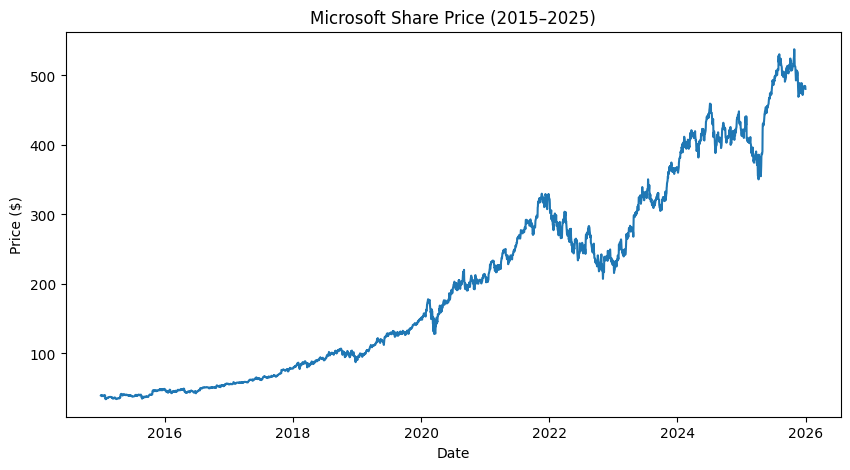

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(data.index, data['MSFT'])
plt.title('Microsoft Share Price (2015–2025)')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.show()

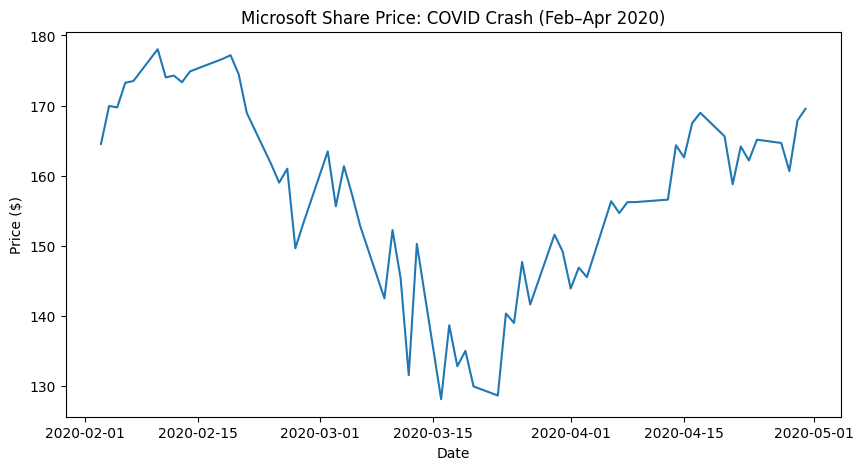

In [23]:
# Plot just the COVID period
plt.figure(figsize=(10, 5))
plt.plot(covid_period.index, covid_period['MSFT'])
plt.title('Microsoft Share Price: COVID Crash (Feb–Apr 2020)')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.show()

plt comes from the Matplotlib library we loaded in Step 5.
Discussion: the price trends upwards over time. That’s why, in finance, we turn prices into returns (Part 1 of the lecture).

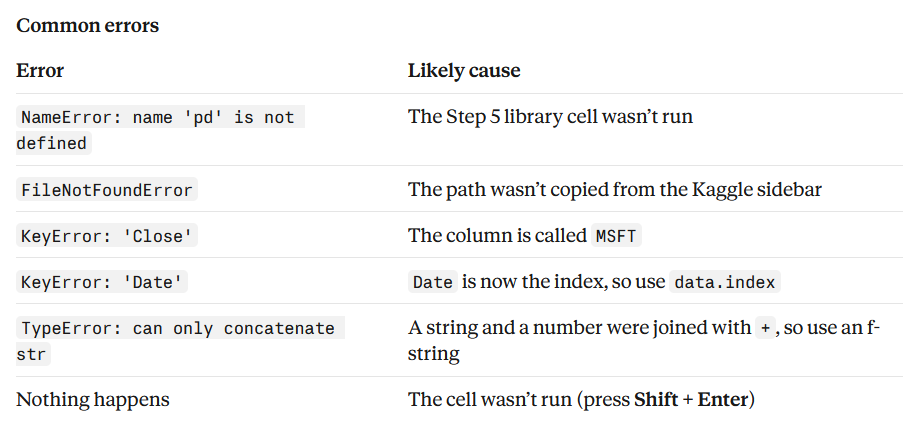